# Deteksi Bak Sampah & Sampah Plastik + Level Sampah – Kampus ITERA
Notebook ini menjalankan **alur deteksi** sesuai diagram alir penelitian, terpisah dari web dashboard (`app.py`).
Model **YOLOv8-seg** dilatih sendiri dari foto berlabel (Label Studio) dengan **2 kelas**:

| Kelas | Bentuk label | Fungsi |
|---|---|---|
| `box_sampah` | poligon (garis keliling bak bata) | menentukan **area bak** |
| `sampah_plastik` | kotak | setiap kantong/sampah plastik |

Dari 2 deteksi itu dihitung:
- **Level sampah (%)** = luas lantai bak yang tertutup plastik ÷ luas bak.
- **Status bak**: kosong / sebagian / penuh (berdasarkan level).
- **Berserakan**: ada plastik yang berada **di luar** poligon bak.

```mermaid
flowchart TD
  A([Mulai]) --> B[Webcam / folder mengambil gambar sampah] --> C[Input citra] --> D[Preprocessing citra]
  D --> E[Resize & normalisasi] --> F[Backbone] --> G[Ekstraksi fitur citra] --> H[Neck] --> I[Fusi fitur]
  I --> J[Detection head] --> K[Prediksi bounding box, kelas, confidence, mask] --> L[Non-Maximum Suppression]
  L --> M{Hasil deteksi valid?<br/>bak terdeteksi}
  M -- Tidak --> B
  M -- Ya --> N[Hitung level: plastik di dalam vs di luar bak] --> O{Kategori}
  O --> P[Kosong] & P2[Sebagian] & Q[Berserakan] & R[Penuh]
  P & P2 & Q & R --> S[Hasil deteksi] --> T[Tampilkan di website] --> U[Simpan data monitoring] --> V[Kirim WhatsApp ke petugas] --> W([Selesai])
```

**Urutan pakai:** jalankan semua sel dari atas (Run All). Jika `models/best.pt` belum ada, bagian 3 otomatis melatih model
(butuh folder `samplefoto/` hasil ekspor Label Studio).

## 0. Khusus Google Colab
Di Google Colab, sel ini menyambungkan Google Drive, masuk ke folder proyek, lalu memasang `ultralytics`.
Di laptop sendiri (VS Code / Jupyter) sel ini **otomatis dilewati**.

Persiapan di Colab: unggah folder **TA_Sampah** (isi file zip) ke **Google Drive → My Drive**, lalu pilih
**Runtime → Change runtime type → T4 GPU** supaya cepat.

In [1]:
import os, sys, subprocess
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    FOLDER_PROYEK = "/content/drive/MyDrive/TA_Sampah"   # ganti jika foldernya diberi nama/lokasi lain
    os.chdir(FOLDER_PROYEK)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"], check=True)
    print("Folder kerja:", os.getcwd())
    print("Isi folder  :", sorted(os.listdir(".")))
else:
    print("Bukan Google Colab -> lewati. Folder kerja:", os.getcwd())

Bukan Google Colab -> lewati. Folder kerja: C:\Users\telkom\Music\TA_JOKI


## 1. Import

In [2]:
# Jalankan sekali jika paket belum ada (hapus tanda # di bawah)
# %pip install ultralytics matplotlib pandas
import os, glob, time, json, base64, sqlite3, csv, subprocess, sys
from datetime import datetime
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torchvision
import torch.nn.functional as F

DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print("torch", torch.__version__, "| device:", DEVICE)

torch 2.14.1+cu126 | device: cuda


## 2. Konfigurasi
Ubah nilai di sel ini sesuai kebutuhan pengujian.

In [3]:
MODEL_PATH = "models/best.pt"         # model hasil training (bagian 3)
SUMBER     = "folder"                 # "folder" = foto di FOLDER_UJI, "webcam" = kamera laptop/USB
FOLDER_UJI = "dataset/images/test"    # foto UJI (tidak dipakai saat training). Boleh diganti folder foto lain
WEBCAM_INDEX, MAKS_ULANG = 0, 3

IMG_SIZE = 640     # ukuran input jaringan (resize + letterbox), sama dengan saat training
CONF_TH  = 0.35    # ambang confidence deteksi
IOU_TH   = 0.50    # ambang IoU untuk Non-Maximum Suppression
DENOISE  = False   # True: haluskan noise kamera (bilateral filter). Model dilatih tanpa filter, jadi bawaan False

KELAS_BAK, KELAS_PLASTIK = "box_sampah", "sampah_plastik"
MIN_DI_DALAM   = 0.50   # plastik dianggap DI DALAM bak jika >= 50% kotaknya berada di area bak
AMBANG_KOSONG  = 10.0   # level < 10%  -> bak kosong
AMBANG_PENUH   = 50.0   # level >= 50% -> bak penuh (lihat bagian 8 untuk dasar pemilihan)
MIN_BERSERAKAN = 1      # jumlah plastik di luar bak agar dianggap berserakan

LOKASI, KAMERA = "Area Gedung A ITERA", "CCTV-01"
OUTPUT_DIR = "notebook_output"; os.makedirs(f"{OUTPUT_DIR}/hasil", exist_ok=True)

# --- integrasi (opsional) ---
KIRIM_KE_WEB = False                  # True: kirim hasil ke web dashboard (python app.py harus jalan, URL CCTV = eksternal)
WEB_URL      = "http://localhost:5000"
WA_MODE      = "simulasi"             # "simulasi" (cetak pesan) | "fonnte"
FONNTE_TOKEN = ""                     # isi jika WA_MODE = "fonnte"
WA_TUJUAN    = ["081234567890"]       # nomor petugas kebersihan

## 3. Model: latih jika belum ada
Training hanya perlu **sekali**. Langkahnya:
1. `siapkan_dataset.py` – menyalin foto dari `samplefoto/` (ekspor Label Studio), memutar foto sesuai EXIF, memperkecil ke
   1280 px, mengubah label kotak plastik menjadi poligon (karena label bak berupa poligon), lalu membagi
   **train/val/test per blok waktu** agar foto beruntun yang mirip tidak bocor ke data uji.
2. `latih_model.py` – melatih **YOLOv8s-seg** (pralatih COCO) dan menyalin hasil terbaik ke `models/best.pt`.
   Dipakai `overlap_mask=False`: mask bak & mask plastik disimpan terpisah. Jika tidak, mask plastik "menimpa" mask bak
   saat training sehingga model belajar bak yang bolong di posisi plastik.

Set `LATIH = True` untuk melatih ulang (misalnya setelah menambah foto berlabel).

In [4]:
LATIH = not os.path.exists(MODEL_PATH)
if LATIH:
    if not os.path.isdir("dataset"):
        subprocess.run([sys.executable, "siapkan_dataset.py"], check=True)
    subprocess.run([sys.executable, "latih_model.py"], check=True)   # GPU dipakai otomatis jika ada (~1 jam RTX 3050)
else:
    print("Model sudah ada:", MODEL_PATH, "-> lewati training (set LATIH = True untuk melatih ulang)")

Model sudah ada: models/best.pt -> lewati training (set LATIH = True untuk melatih ulang)


## 4. Memuat model
Arsitektur YOLOv8-seg dibagi menjadi **backbone** (ekstraksi fitur), **neck** (fusi fitur beberapa skala) dan
**head** (`Segment`: kotak + kelas + confidence + koefisien mask).

In [5]:
from ultralytics import YOLO

yolo = YOLO(MODEL_PATH)
net = yolo.model.to(DEVICE).eval()
KELAS = [yolo.names[i] for i in sorted(yolo.names)]
NC = len(KELAS)
print("Kelas:", KELAS)

layers = list(net.model)
neck_mulai = next(i for i, l in enumerate(layers) if type(l).__name__ == "Upsample")
BACKBONE = list(range(0, neck_mulai))
NECK     = list(range(neck_mulai, len(layers) - 1))
HEAD     = len(layers) - 1
FUSI     = [i for i in NECK if type(layers[i]).__name__ == "Concat"]
SKALA_HEAD = layers[HEAD].f            # output neck yang masuk ke head (P3, P4, P5)
print(pd.DataFrame([{"layer": i, "modul": type(l).__name__,
                     "bagian": "backbone" if i in BACKBONE else "head" if i == HEAD else "neck",
                     "input dari": l.f} for i, l in enumerate(layers)]).to_string(index=False))

Kelas: ['box_sampah', 'sampah_plastik']
 layer    modul   bagian   input dari
     0     Conv backbone           -1
     1     Conv backbone           -1
     2      C2f backbone           -1
     3     Conv backbone           -1
     4      C2f backbone           -1
     5     Conv backbone           -1
     6      C2f backbone           -1
     7     Conv backbone           -1
     8      C2f backbone           -1
     9     SPPF backbone           -1
    10 Upsample     neck           -1
    11   Concat     neck      [-1, 6]
    12      C2f     neck           -1
    13 Upsample     neck           -1
    14   Concat     neck      [-1, 4]
    15      C2f     neck           -1
    16     Conv     neck           -1
    17   Concat     neck     [-1, 12]
    18      C2f     neck           -1
    19     Conv     neck           -1
    20   Concat     neck      [-1, 9]
    21      C2f     neck           -1
    22  Segment     head [15, 18, 21]


## 5. Fungsi untuk setiap tahap alur
Setiap fungsi di bawah mewakili satu kotak pada diagram alir.

In [6]:
# 5.1 Webcam / folder mengambil gambar sampah
def ambil_gambar():
    # Generator: (nama, path_label_asli_atau_None, gambar_BGR)
    if SUMBER == "webcam":
        cap = cv2.VideoCapture(WEBCAM_INDEX)
        try:
            while True:
                ok, frame = cap.read()
                yield (f"webcam_{datetime.now():%H%M%S}", None, frame if ok else None)
        finally:
            cap.release()
    else:
        for f in sorted(glob.glob(os.path.join(FOLDER_UJI, "*.*"))):
            if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp")):
                lbl = os.path.splitext(f.replace("\\", "/").replace("/images/", "/labels/"))[0] + ".txt"
                yield (os.path.basename(f), lbl if os.path.isfile(lbl) else None, cv2.imread(f))

# 5.2 Input citra
def input_citra(img):
    if img is None or img.size == 0:
        raise ValueError("Gambar kosong / kamera tidak terbaca")
    return img

# 5.3 Preprocessing citra: (opsional) peredaman noise, lalu BGR (OpenCV) -> RGB (urutan warna model)
def preprocessing(img_bgr):
    if DENOISE:
        img_bgr = cv2.bilateralFilter(img_bgr, 5, 40, 40)
    return cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

# 5.4 Resize (letterbox 640x640, rasio dijaga) + normalisasi piksel 0-1 -> tensor N,C,H,W
def resize_normalisasi(img_rgb, size=IMG_SIZE):
    h, w = img_rgb.shape[:2]
    r = min(size / h, size / w)
    nh, nw = round(h * r), round(w * r)
    top, left = (size - nh) // 2, (size - nw) // 2
    canvas = np.full((size, size, 3), 114, np.uint8)
    canvas[top:top + nh, left:left + nw] = cv2.resize(img_rgb, (nw, nh), interpolation=cv2.INTER_LINEAR)
    tensor = torch.from_numpy(canvas).permute(2, 0, 1).float().unsqueeze(0) / 255.0
    return tensor.to(DEVICE), canvas, {"r": r, "pad": (left, top), "asli": (h, w), "baru": (nh, nw)}

In [7]:
# 5.5–5.9 Backbone -> ekstraksi fitur -> neck -> fusi fitur -> detection head
def forward_dengan_fitur(tensor):
    fitur, hooks = {}, []
    for i in BACKBONE + NECK + [HEAD]:
        def hook(_m, _inp, out, i=i):
            fitur[i] = out
        hooks.append(layers[i].register_forward_hook(hook))
    with torch.no_grad():
        out = net(tensor)
    for h in hooks:
        h.remove()
    # keluaran Segment: (prediksi [1, 4+kelas+32, anchor], proto mask [1, 32, 160, 160])
    pred, proto = out[0] if isinstance(out[0], (list, tuple)) else out
    return pred, proto, fitur

def tampilkan_peta_fitur(fitur, idx, judul):
    fig, axs = plt.subplots(1, len(idx), figsize=(3.2 * len(idx), 3.2))
    for ax, i in zip(np.atleast_1d(axs), idx):
        t = fitur[i]
        while isinstance(t, (list, tuple, dict)):
            t = t[0] if not isinstance(t, dict) else next(iter(t.values()))
        ax.imshow(t[0].float().mean(0).cpu().numpy(), cmap="magma")
        ax.set_title(f"L{i} {type(layers[i]).__name__}\n{tuple(t.shape[1:])}", fontsize=9); ax.axis("off")
    fig.suptitle(judul); plt.tight_layout(); plt.show()

In [8]:
# 5.10 Prediksi bounding box, kelas, confidence (+ koefisien mask) dari keluaran head
def decode_prediksi(pred, proto, conf_th=CONF_TH):
    p = pred[0].T                                         # [anchor, 4 + kelas + 32]
    conf, cls = p[:, 4:4 + NC].max(1)
    keep = conf >= conf_th
    xywh = p[keep, :4]
    xyxy = torch.cat([xywh[:, :2] - xywh[:, 2:] / 2, xywh[:, :2] + xywh[:, 2:] / 2], 1)
    return {"xyxy": xyxy, "conf": conf[keep], "cls": cls[keep], "koef": p[keep, 4 + NC:],
            "proto": proto[0], "kandidat_total": p.shape[0]}

def _ke_asli(xyxy, meta):
    xy = xyxy.clone(); left, top = meta["pad"]
    xy[:, [0, 2]] -= left; xy[:, [1, 3]] -= top; xy /= meta["r"]
    h, w = meta["asli"]
    xy[:, [0, 2]] = xy[:, [0, 2]].clamp(0, w); xy[:, [1, 3]] = xy[:, [1, 3]].clamp(0, h)
    return xy

def _mask_bak(koef, proto, box640, meta):
    # mask = sigmoid(koef · proto), dipotong sesuai kotak, lalu dikembalikan ke ukuran gambar asli
    c, mh, mw = proto.shape
    m = torch.sigmoid(koef @ proto.float().view(c, -1)).view(1, 1, mh, mw)
    m = F.interpolate(m, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False)[0, 0]
    x1, y1, x2, y2 = box640.int().tolist()
    potong = torch.zeros_like(m); potong[max(0, y1):y2, max(0, x1):x2] = 1
    m = (m * potong).cpu().numpy()
    left, top = meta["pad"]; nh, nw = meta["baru"]; h, w = meta["asli"]
    m = cv2.resize(m[top:top + nh, left:left + nw], (w, h), interpolation=cv2.INTER_LINEAR)
    return rapikan_mask((m > 0.5).astype(np.uint8))

def rapikan_mask(m):
    # Bak bata berbentuk segi empat (cembung): ambil garis luar terbesar lalu tutup penuh (convex hull),
    # supaya lubang/takik kecil di mask (mis. tertutup kantong plastik) tetap dihitung sebagai area bak
    kontur, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not kontur:
        return m
    penuh = np.zeros_like(m)
    cv2.fillPoly(penuh, [cv2.convexHull(max(kontur, key=cv2.contourArea))], 1)
    return penuh

# 5.11 Non-Maximum Suppression: buang kotak tumpang-tindih (IoU > IOU_TH) per kelas
def nms(k, meta, iou_th=IOU_TH):
    keep = torchvision.ops.batched_nms(k["xyxy"], k["conf"], k["cls"], iou_th)
    xy = _ke_asli(k["xyxy"][keep], meta)
    deteksi = []
    for j, idx in enumerate(keep.tolist()):
        d = {"kelas": KELAS[int(k["cls"][idx])], "conf": float(k["conf"][idx]), "box": [float(v) for v in xy[j]]}
        if d["kelas"] == KELAS_BAK:
            d["mask"] = _mask_bak(k["koef"][idx], k["proto"], k["xyxy"][idx], meta)
        deteksi.append(d)
    return deteksi

# 5.12 Hasil deteksi valid? -> bak sampah harus terdeteksi (tanpa bak, level tidak bisa dihitung)
def deteksi_valid(deteksi):
    return any(d["kelas"] == KELAS_BAK for d in deteksi)

In [9]:
# 5.13 Klasifikasi kondisi: hitung level & plastik di dalam / di luar bak
def bak_utama(deteksi):
    bak = [d for d in deteksi if d["kelas"] == KELAS_BAK]
    return max(bak, key=lambda d: d["conf"] * d["mask"].sum()) if bak else None

def hitung_level(mask_bak, plastik):
    tutup = np.zeros_like(mask_bak)
    dalam, luar = [], []
    for d in plastik:
        x1, y1, x2, y2 = map(int, d["box"])
        bagian = mask_bak[y1:y2, x1:x2]
        if bagian.size and bagian.mean() >= MIN_DI_DALAM:
            dalam.append(d); tutup[y1:y2, x1:x2] = 1
        else:
            luar.append(d)
    level = float((tutup & mask_bak).sum() / max(1, mask_bak.sum()) * 100)
    return level, dalam, luar

def status_dari_level(level):
    return "kosong" if level < AMBANG_KOSONG else "penuh" if level >= AMBANG_PENUH else "sebagian"

def klasifikasi_kondisi(img_bgr, deteksi):
    bak = bak_utama(deteksi)
    plastik = [d for d in deteksi if d["kelas"] == KELAS_PLASTIK]
    level, dalam, luar = hitung_level(bak["mask"], plastik)
    status_bak = status_dari_level(level)
    berserakan = len(luar) >= MIN_BERSERAKAN
    # kategori utama (dipakai web & WhatsApp): penuh > berserakan > kosong/sebagian
    kategori = "penuh" if status_bak == "penuh" else "berserakan" if berserakan else status_bak
    return kategori, {"level": round(level, 1), "status_bak": status_bak, "berserakan": berserakan,
                      "plastik_dalam": len(dalam), "plastik_luar": len(luar), "conf_bak": round(bak["conf"], 3),
                      "_bak": bak, "_dalam": dalam, "_luar": luar}

In [10]:
WARNA = {"penuh": (30, 30, 200), "berserakan": (0, 140, 230), "sebagian": (0, 170, 200), "kosong": (60, 160, 60)}

# 5.14 Hasil deteksi: gambar beranotasi (bak = poligon biru muda, plastik hijau = di dalam, merah = di luar)
def gambar_hasil(img_bgr, kategori, info):
    out = img_bgr.copy(); H, W = out.shape[:2]; t = max(2, W // 400)
    bak = info["_bak"]["mask"]
    warna_bak = np.zeros_like(out); warna_bak[bak > 0] = (230, 200, 0)
    out = cv2.addWeighted(out, 1, warna_bak, 0.25, 0)
    kontur, _ = cv2.findContours(bak, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(out, kontur, -1, (230, 200, 0), t + 1)
    for d, col in [(d, (60, 200, 60)) for d in info["_dalam"]] + [(d, (40, 40, 230)) for d in info["_luar"]]:
        x1, y1, x2, y2 = map(int, d["box"])
        cv2.rectangle(out, (x1, y1), (x2, y2), col, t)
    fs = W / 1100
    label = f"LEVEL {info['level']:.0f}% - BAK {info['status_bak'].upper()}"
    if info["berserakan"]:
        label += f" - {info['plastik_luar']} PLASTIK DI LUAR (BERSERAKAN)"
    bar = int(46 * fs) + 10
    cv2.rectangle(out, (0, 0), (W, bar), WARNA[kategori], -1)
    cv2.putText(out, label, (12, bar - 14), cv2.FONT_HERSHEY_SIMPLEX, fs, (255, 255, 255), max(2, t), cv2.LINE_AA)
    cv2.putText(out, f"{KAMERA} | {LOKASI} | {datetime.now():%d/%m/%Y %H:%M:%S}", (12, H - 14),
                cv2.FONT_HERSHEY_SIMPLEX, fs * .6, (255, 255, 255), max(1, t - 1), cv2.LINE_AA)
    return out

def tampil(img_bgr, judul="", w=9):
    plt.figure(figsize=(w, w * img_bgr.shape[0] / img_bgr.shape[1]))
    plt.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)); plt.title(judul); plt.axis("off"); plt.show()

In [11]:
# 5.15 Menampilkan hasil pada website (opsional): kirim ke endpoint /api/detections milik app.py.
#      Di web, set URL streaming CCTV = "eksternal" agar hasil notebook yang tampil.
def api_key_web():
    try:
        con = sqlite3.connect("data/sampah.db")
        v = con.execute("SELECT setting_value FROM system_settings WHERE setting_key='ingest_api_key'").fetchone()
        con.close(); return v[0] if v else ""
    except sqlite3.Error:
        return ""

def tampilkan_di_website(img_bgr, kategori, info, ulang=3):
    if not KIRIM_KE_WEB:
        return "dilewati (KIRIM_KE_WEB=False)"
    import requests
    H, W = img_bgr.shape[:2]
    norm = lambda b: [b[0] / W, b[1] / H, b[2] / W, b[3] / H]
    boxes = [{"kind": info["status_bak"], "conf": info["conf_bak"], "box": norm(info["_bak"]["box"])}]
    boxes += [{"kind": "berserakan", "conf": round(d["conf"], 2), "box": norm(d["box"])} for d in info["_luar"]]
    _, jpg = cv2.imencode(".jpg", gambar_hasil(img_bgr, kategori, info), [cv2.IMWRITE_JPEG_QUALITY, 80])
    body = {"boxes": boxes, "fullness": info["level"], "image": base64.b64encode(jpg).decode()}
    try:
        for _ in range(ulang):    # web mencatat kondisi setelah stabil beberapa frame
            r = requests.post(f"{WEB_URL}/api/detections", json=body, headers={"X-API-Key": api_key_web()}, timeout=10)
        return f"terkirim (HTTP {r.status_code})"
    except requests.RequestException as e:
        return f"gagal: {e.__class__.__name__}"

# 5.16 Menyimpan data monitoring (CSV + gambar bukti)
CSV_PATH = f"{OUTPUT_DIR}/monitoring.csv"
def simpan_monitoring(nama, kategori, info, img_hasil):
    path_img = f"{OUTPUT_DIR}/hasil/{datetime.now():%Y%m%d_%H%M%S}_{os.path.splitext(nama)[0]}_{kategori}.jpg"
    cv2.imwrite(path_img, img_hasil)
    baris = {"waktu": datetime.now().strftime("%Y-%m-%d %H:%M:%S"), "gambar": nama, "kategori": kategori,
             "level_persen": info["level"], "status_bak": info["status_bak"], "berserakan": info["berserakan"],
             "plastik_dalam": info["plastik_dalam"], "plastik_luar": info["plastik_luar"],
             "lokasi": LOKASI, "kamera": KAMERA, "bukti": path_img}
    baru = not os.path.exists(CSV_PATH)
    with open(CSV_PATH, "a", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=list(baris)); w.writeheader() if baru else None; w.writerow(baris)
    return baris

# 5.17 Mengirim notifikasi WhatsApp kepada petugas (hanya kondisi penuh / berserakan)
def pesan_wa(kategori, info):
    waktu = datetime.now().strftime("%H:%M WIB")
    if kategori == "penuh":
        return (f"⚠️ ALERT SAMPAH – KAMPUS ITERA\n\nTerdeteksi bak sampah penuh.\n\n- Lokasi: {LOKASI}\n- CCTV: {KAMERA}\n"
                f"- Level sampah: {info['level']:.0f}%\n- Waktu: {waktu}\n\n"
                "Mohon petugas segera melakukan pengecekan dan pengangkutan sampah.")
    return (f"⚠️ PERINGATAN SAMPAH BERSERAKAN\n\nSistem mendeteksi {info['plastik_luar']} sampah plastik di luar bak.\n\n"
            f"- Lokasi: {LOKASI}\n- CCTV: {KAMERA}\n- Level bak: {info['level']:.0f}%\n- Waktu: {waktu}\n\n"
            "Mohon dilakukan pembersihan area.")

def kirim_whatsapp(kategori, info):
    if kategori not in ("penuh", "berserakan"):
        return f"tidak perlu (kondisi {kategori})"
    teks = pesan_wa(kategori, info)
    if WA_MODE == "fonnte" and FONNTE_TOKEN:
        import requests
        hasil = []
        for no in WA_TUJUAN:
            r = requests.post("https://api.fonnte.com/send", headers={"Authorization": FONNTE_TOKEN},
                              data={"target": no, "message": teks, "countryCode": "62"}, timeout=15)
            hasil.append(f"{no}: {r.status_code}")
        return "fonnte " + ", ".join(hasil)
    return "simulasi (pesan tidak dikirim)\n" + teks

## 6. Jalankan alur lengkap untuk satu gambar (langkah demi langkah)
Ganti `CONTOH` untuk mencoba foto lain.

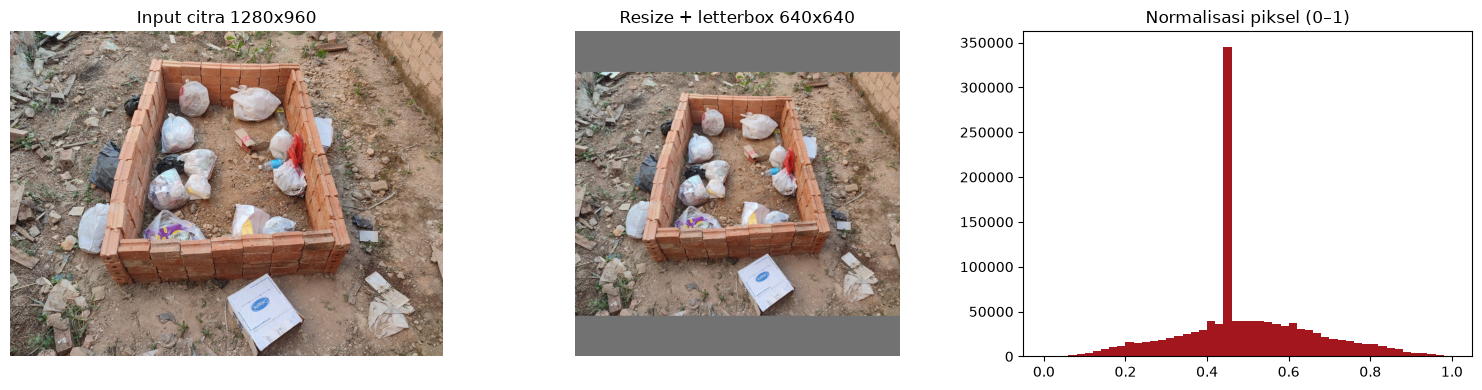

Tensor input: (1, 3, 640, 640) min 0.0 max 1.0


In [12]:
CONTOH = sorted(glob.glob(os.path.join(FOLDER_UJI, "*.jpg")))[0]

img = input_citra(cv2.imread(CONTOH))           # Input citra
rgb = preprocessing(img)                          # Preprocessing citra
tensor, kanvas, meta = resize_normalisasi(rgb)    # Resize & normalisasi

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax[0].set_title(f"Input citra {img.shape[1]}x{img.shape[0]}")
ax[1].imshow(kanvas); ax[1].set_title(f"Resize + letterbox {IMG_SIZE}x{IMG_SIZE}")
ax[2].hist(tensor.cpu().numpy().ravel(), bins=50, color="#a3161e"); ax[2].set_title("Normalisasi piksel (0–1)")
ax[0].axis("off"); ax[1].axis("off"); plt.tight_layout(); plt.show()
print("Tensor input:", tuple(tensor.shape), "min", float(tensor.min()), "max", float(tensor.max()))

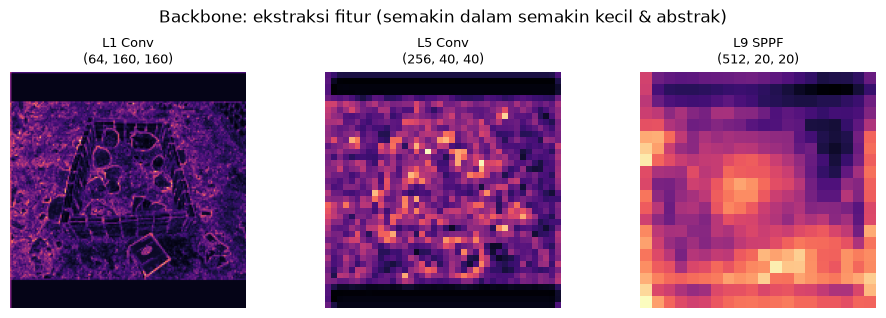

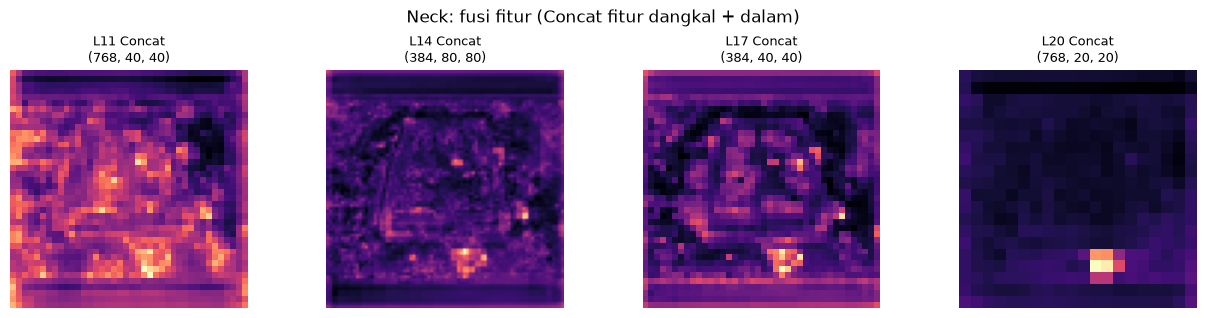

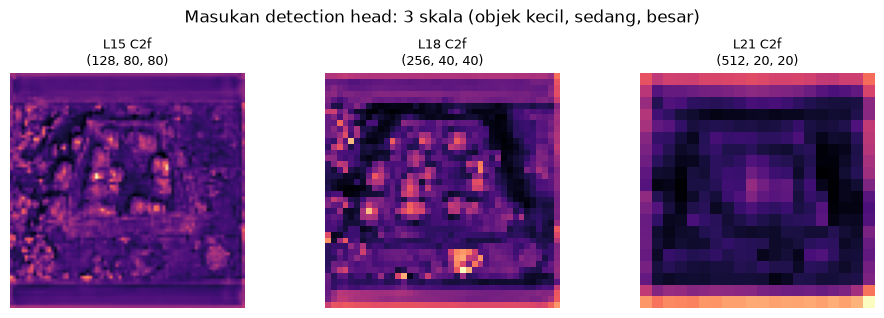

Keluaran detection head: (1, 38, 8400) -> (batch, 4 koordinat + 2 skor kelas + 32 koef. mask, jumlah anchor)
Proto mask: (1, 32, 160, 160) -> 32 pola dasar yang dikombinasikan menjadi bentuk bak


In [13]:
# Backbone -> ekstraksi fitur -> neck -> fusi fitur -> detection head
pred, proto, fitur = forward_dengan_fitur(tensor)
tampilkan_peta_fitur(fitur, [BACKBONE[1], BACKBONE[len(BACKBONE) // 2], BACKBONE[-1]],
                     "Backbone: ekstraksi fitur (semakin dalam semakin kecil & abstrak)")
tampilkan_peta_fitur(fitur, FUSI, "Neck: fusi fitur (Concat fitur dangkal + dalam)")
tampilkan_peta_fitur(fitur, SKALA_HEAD, "Masukan detection head: 3 skala (objek kecil, sedang, besar)")
print("Keluaran detection head:", tuple(pred.shape), f"-> (batch, 4 koordinat + {NC} skor kelas + 32 koef. mask, jumlah anchor)")
print("Proto mask:", tuple(proto.shape), "-> 32 pola dasar yang dikombinasikan menjadi bentuk bak")

Anchor total: 8400 | lolos confidence >= 0.35: 166 | setelah NMS: 17 {'sampah_plastik': 16, 'box_sampah': 1}


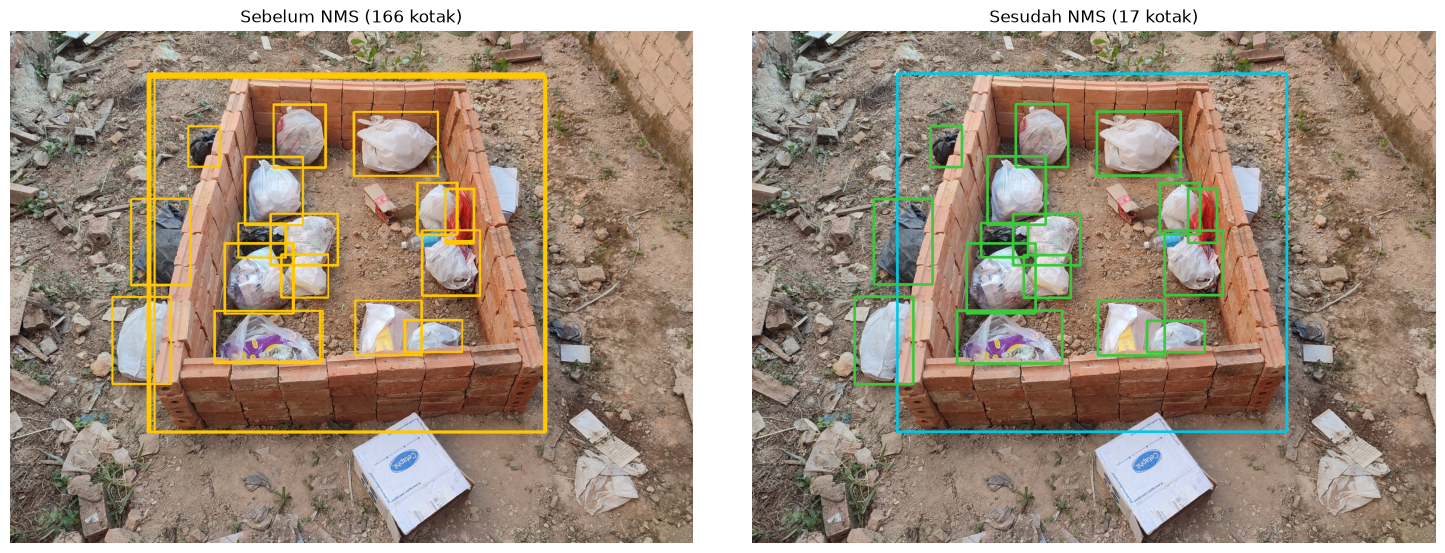

In [14]:
# Prediksi bounding box, kelas, confidence -> Non-Maximum Suppression
kandidat = decode_prediksi(pred, proto)
deteksi = nms(kandidat, meta)
jumlah = pd.Series([d["kelas"] for d in deteksi]).value_counts().to_dict()
print(f"Anchor total: {kandidat['kandidat_total']} | lolos confidence >= {CONF_TH}: {len(kandidat['conf'])} | setelah NMS: {len(deteksi)} {jumlah}")

sebelum, sesudah = img.copy(), img.copy()
for b in _ke_asli(kandidat["xyxy"], meta).int().tolist():
    cv2.rectangle(sebelum, tuple(b[:2]), tuple(b[2:]), (0, 200, 255), 2)
for d in deteksi:
    col = (230, 200, 0) if d["kelas"] == KELAS_BAK else (60, 200, 60)
    cv2.rectangle(sesudah, tuple(map(int, d["box"][:2])), tuple(map(int, d["box"][2:])), col, 3)
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
ax[0].imshow(cv2.cvtColor(sebelum, cv2.COLOR_BGR2RGB)); ax[0].set_title(f"Sebelum NMS ({len(kandidat['conf'])} kotak)")
ax[1].imshow(cv2.cvtColor(sesudah, cv2.COLOR_BGR2RGB)); ax[1].set_title(f"Sesudah NMS ({len(deteksi)} kotak)")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

Hasil deteksi valid? Ya (bak terdeteksi)
{'level': 33.5, 'status_bak': 'sebagian', 'berserakan': True, 'plastik_dalam': 13, 'plastik_luar': 3, 'conf_bak': 0.964}
Kategori kondisi: BERSERAKAN


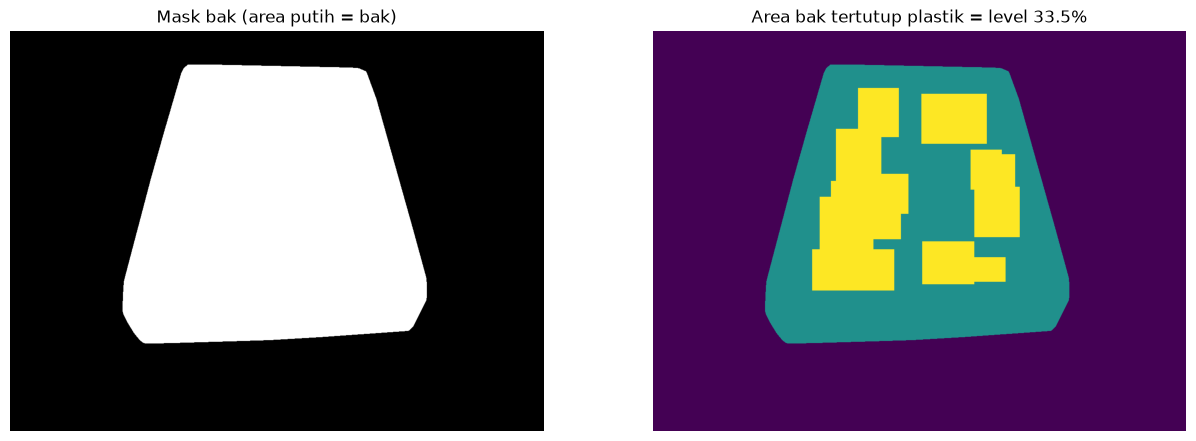

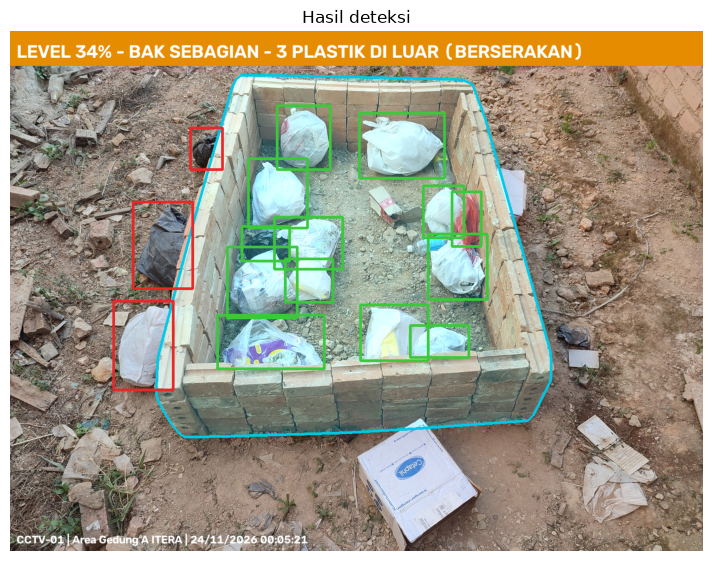

Website      : dilewati (KIRIM_KE_WEB=False)
Penyimpanan  : notebook_output/hasil/20261124_000521_060155c0-IMG_20260914_153558_berserakan.jpg
WhatsApp     : simulasi (pesan tidak dikirim)
⚠️ PERINGATAN SAMPAH BERSERAKAN

Sistem mendeteksi 3 sampah plastik di luar bak.

- Lokasi: Area Gedung A ITERA
- CCTV: CCTV-01
- Level bak: 34%
- Waktu: 00:05 WIB

Mohon dilakukan pembersihan area.


In [15]:
# Hasil deteksi valid?  Ya -> hitung level & klasifikasi kondisi
print("Hasil deteksi valid?", "Ya (bak terdeteksi)" if deteksi_valid(deteksi) else "Tidak (bak tidak terlihat) -> ambil gambar lagi")
kategori, info = klasifikasi_kondisi(img, deteksi)
print({k: v for k, v in info.items() if not k.startswith("_")})
print("Kategori kondisi:", kategori.upper())

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].imshow(info["_bak"]["mask"], cmap="gray"); ax[0].set_title("Mask bak (area putih = bak)")
tutup = np.zeros_like(info["_bak"]["mask"])
for d in info["_dalam"]:
    x1, y1, x2, y2 = map(int, d["box"]); tutup[y1:y2, x1:x2] = 1
ax[1].imshow(info["_bak"]["mask"] + (tutup & info["_bak"]["mask"]), cmap="viridis")
ax[1].set_title(f"Area bak tertutup plastik = level {info['level']:.1f}%")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

hasil = gambar_hasil(img, kategori, info)
tampil(hasil, "Hasil deteksi")
print("Website      :", tampilkan_di_website(img, kategori, info))
print("Penyimpanan  :", simpan_monitoring(os.path.basename(CONTOH), kategori, info, hasil)["bukti"])
print("WhatsApp     :", kirim_whatsapp(kategori, info))

## 7. Alur lengkap untuk semua gambar
Menjalankan diagram alir dari **Mulai** sampai **Selesai** untuk setiap foto di `FOLDER_UJI`. Jika bak tidak terdeteksi,
alur kembali ke pengambilan gambar (webcam: ambil ulang sampai `MAKS_ULANG`; folder: lanjut ke foto berikutnya).

In [16]:
def proses(img):
    tensor, _, meta = resize_normalisasi(preprocessing(img))
    pred, proto, _ = forward_dengan_fitur(tensor)
    return nms(decode_prediksi(pred, proto), meta)

def jalankan_alur(tampilkan_gambar=False, kirim_wa=False, batas=None):
    rekap, ulang = [], 0
    for n, (nama, label, img) in enumerate(ambil_gambar()):
        if batas and n >= batas:
            break
        t0 = time.perf_counter()
        try:
            img = input_citra(img)
        except ValueError as e:
            print(nama, "->", e); continue
        deteksi = proses(img)
        if not deteksi_valid(deteksi):
            print(f"{nama}: bak tidak terdeteksi -> ambil gambar lagi")
            rekap.append({"gambar": nama, "kategori": "tidak valid", "_label": label})
            ulang += 1
            if SUMBER == "webcam" and ulang >= MAKS_ULANG:
                break
            continue
        ulang = 0
        kategori, info = klasifikasi_kondisi(img, deteksi)
        hasil = gambar_hasil(img, kategori, info)
        ms = (time.perf_counter() - t0) * 1000
        web = tampilkan_di_website(img, kategori, info)
        simpan_monitoring(nama, kategori, info, hasil)
        wa = kirim_whatsapp(kategori, info) if kirim_wa else "-"
        rekap.append({"gambar": nama, "kategori": kategori, **{k: v for k, v in info.items() if not k.startswith("_")},
                      "waktu_ms": round(ms), "web": web, "_img": hasil, "_label": label, "_shape": img.shape[:2]})
        if tampilkan_gambar:
            tampil(hasil, f"{nama} -> {kategori}", w=6)
        if SUMBER == "webcam":
            break                     # webcam: satu siklus deteksi per pemanggilan
    return rekap

rekap = jalankan_alur()
df = pd.DataFrame([{k: v for k, v in r.items() if not k.startswith("_")} for r in rekap])
print("Rata-rata waktu proses per gambar:", round(df["waktu_ms"].dropna().mean()), "ms di", DEVICE)
df

Rata-rata waktu proses per gambar: 65 ms di cuda


,gambar,kategori,level,status_bak,berserakan,plastik_dalam,plastik_luar,conf_bak,waktu_ms,web
0,060155c0-IMG_20260914_153558.jpg,berserakan,33.5,sebagian,True,13,3,0.964,58,dilewati (KIRIM_KE_WEB=False)
1,0aa17cd7-2026-09-14_00.31.41.jpg,penuh,62.2,penuh,False,16,0,0.978,46,dilewati (KIRIM_KE_WEB=False)
2,1206b70a-IMG_20260914_151851.jpg,berserakan,44.4,sebagian,True,19,7,0.957,66,dilewati (KIRIM_KE_WEB=False)
3,1370698f-IMG_20260914_151901.jpg,berserakan,43.2,sebagian,True,19,7,0.965,67,dilewati (KIRIM_KE_WEB=False)
4,1746d6f5-IMG_20260914_154023.jpg,berserakan,30.0,sebagian,True,13,4,0.973,60,dilewati (KIRIM_KE_WEB=False)
5,1a6b7284-2026-09-14_00.31.16.jpg,sebagian,48.3,sebagian,False,18,0,0.985,45,dilewati (KIRIM_KE_WEB=False)
6,1ebfea59-2026-09-14_00.31.10.jpg,penuh,56.0,penuh,True,20,1,0.985,50,dilewati (KIRIM_KE_WEB=False)
7,22b39f43-IMG_20260914_151853.jpg,berserakan,44.0,sebagian,True,19,7,0.957,63,dilewati (KIRIM_KE_WEB=False)
8,26eddc0b-IMG_20260914_153837.jpg,berserakan,27.5,sebagian,True,12,1,0.975,63,dilewati (KIRIM_KE_WEB=False)
9,29fc9705-IMG_20260914_153600.jpg,berserakan,33.9,sebagian,True,13,3,0.945,61,dilewati (KIRIM_KE_WEB=False)


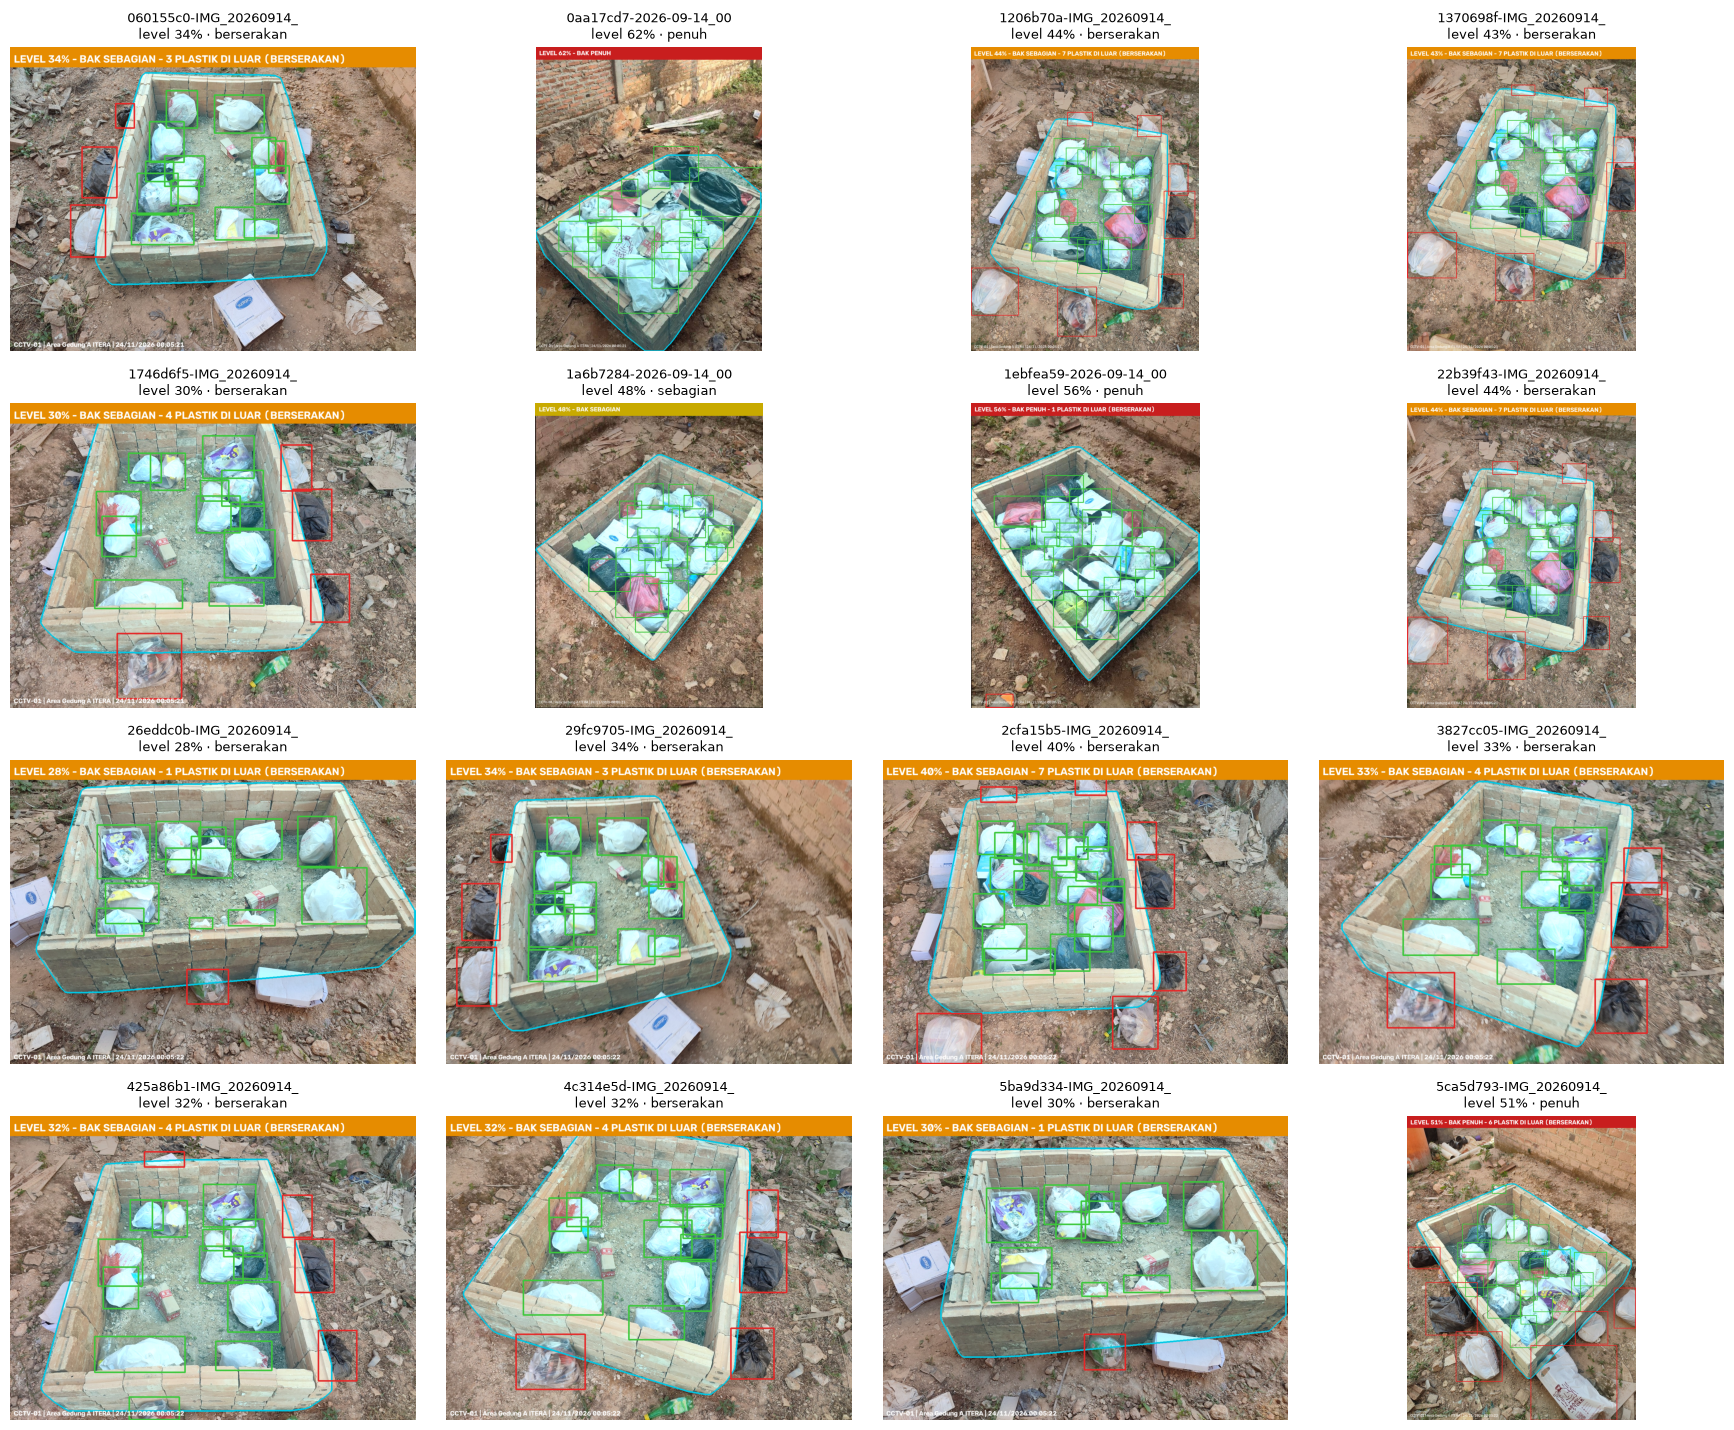

In [17]:
# Galeri hasil
valid = [r for r in rekap if "_img" in r][:16]
kolom = 4; baris = int(np.ceil(len(valid) / kolom))
fig, axs = plt.subplots(baris, kolom, figsize=(4.4 * kolom, 3.6 * baris))
for ax in np.atleast_1d(axs).ravel(): ax.axis("off")
for ax, r in zip(np.atleast_1d(axs).ravel(), valid):
    ax.imshow(cv2.cvtColor(r["_img"], cv2.COLOR_BGR2RGB))
    ax.set_title(f"{r['gambar'][:22]}\nlevel {r['level']:.0f}% · {r['kategori']}", fontsize=9)
plt.tight_layout(); plt.show()

## 8. Evaluasi
Evaluasi dilakukan pada **data uji** (`dataset/images/test`) yang tidak pernah dilihat model saat training.

**8.1 Kemampuan deteksi** – metrik standar YOLO: *precision*, *recall*, *mAP50* dan *mAP50-95*, untuk kotak (box) dan mask.

Ultralytics 8.4.215  Python-3.11.0 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 3050 Ti Laptop GPU, 4096MiB)


YOLOv8s-seg summary (fused): 85 layers, 11,780,374 parameters, 0 gradients, 39.9 GFLOPs


val: Fast image access  (ping: 0.0±0.0 ms, read: 1875.3±592.0 MB/s, size: 478.5 KB)


val: Scanning C:\Users\telkom\Music\TA_JOKI\dataset\labels\test.cache... 40 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 40/40  0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 20% ━━────────── 1/5 48.2s/it 14.5s<3:13

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 40% ━━━━╸─────── 2/5 2.0it/s 14.6s<1.5s

... (2 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 3.0s/it 15.1s

                   all         40        750      0.964      0.969      0.975      0.842      0.964      0.969      0.975      0.794


Speed: 3.3ms preprocess, 11.4ms inference, 0.0ms loss, 2.2ms postprocess per image


,kelas,precision,recall,box mAP50,box mAP50-95,mask mAP50,mask mAP50-95
0,box_sampah,0.988,1.000,0.995,0.988,0.995,0.995
1,sampah_plastik,0.939,0.938,0.955,0.697,0.954,0.593


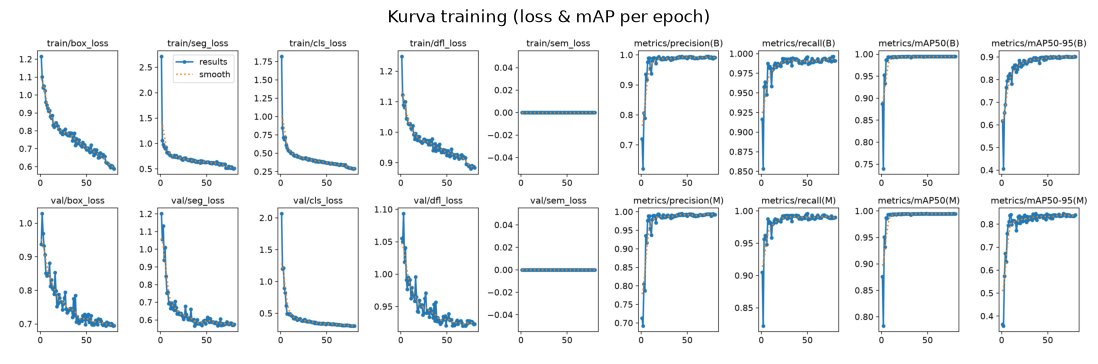

In [18]:
if os.path.isdir("dataset/images/test"):
    import yaml
    # alamat folder dataset disesuaikan dengan laptop yang sedang dipakai (Windows/Mac)
    cfg = {"path": os.path.abspath("dataset"), "train": "images/test", "val": "images/test", "test": "images/test",
           "names": {i: k for i, k in enumerate(KELAS)}}
    with open(f"{OUTPUT_DIR}/data_uji.yaml", "w") as f:
        yaml.safe_dump(cfg, f)
    m = yolo.val(data=f"{OUTPUT_DIR}/data_uji.yaml", split="test", imgsz=IMG_SIZE, batch=8, device=DEVICE, overlap_mask=False,
                 plots=False, verbose=False, project=OUTPUT_DIR, name="val_test", exist_ok=True)
    tabel = []
    for i, k in enumerate(KELAS):
        p, r, ap50, ap = m.box.class_result(i)
        mp, mr, map50, mapx = m.seg.class_result(i)
        tabel.append({"kelas": k, "precision": p, "recall": r, "box mAP50": ap50, "box mAP50-95": ap,
                      "mask mAP50": map50, "mask mAP50-95": mapx})
    display(pd.DataFrame(tabel).round(3))
else:
    print("folder dataset/images/test tidak ada -> lewati (jalankan siapkan_dataset.py)")
if os.path.exists("runs/sampah_seg/results.png"):
    tampil(cv2.imread("runs/sampah_seg/results.png"), "Kurva training (loss & mAP per epoch)", w=14)

**8.2 Ketepatan level & berserakan** – level yang dihitung dari **hasil deteksi model** dibandingkan dengan level
yang dihitung dengan rumus yang sama dari **label asli** (poligon & kotak buatan tangan).

Jumlah foto uji              : 40
MAE level (selisih rata-rata) : 1.8 poin persen
MAE jumlah plastik di dalam   : 0.72
MAE jumlah plastik di luar    : 0.23
Akurasi status bak            : 87.5%
Akurasi berserakan (ya/tidak) : 90.0%


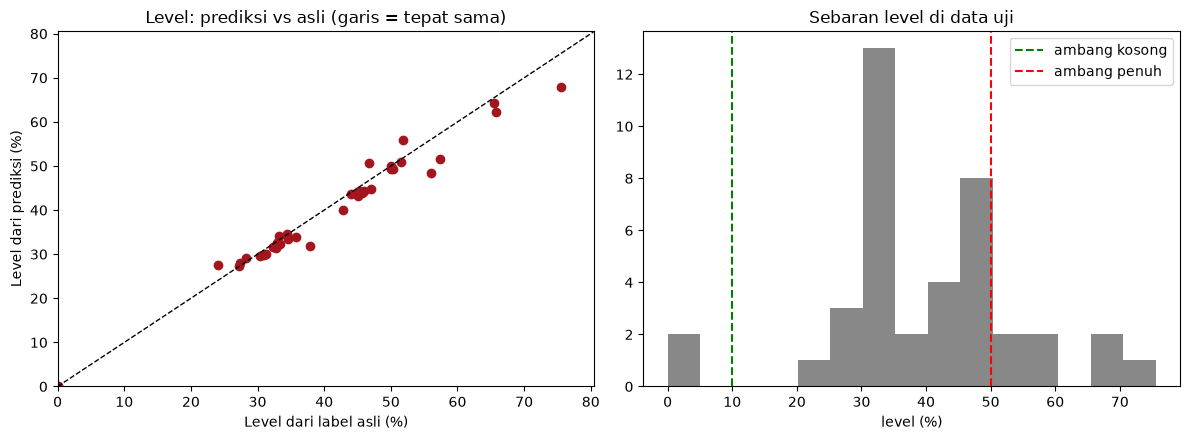

,gambar,level_asli,level_prediksi,dalam_asli,dalam_prediksi,luar_asli,luar_prediksi,status_asli,status_prediksi,berserakan_asli,berserakan_prediksi
0,060155c0-IMG_20260914_153558.jpg,34.5,33.5,13,13,3,3,sebagian,sebagian,True,True
1,0aa17cd7-2026-09-14_00.31.41.jpg,65.8,62.2,17,16,0,0,penuh,penuh,False,False
2,1206b70a-IMG_20260914_151851.jpg,45.9,44.4,19,19,7,7,sebagian,sebagian,True,True
3,1370698f-IMG_20260914_151901.jpg,45.1,43.2,19,19,7,7,sebagian,sebagian,True,True
4,1746d6f5-IMG_20260914_154023.jpg,31.3,30.0,12,13,4,4,sebagian,sebagian,True,True
5,1a6b7284-2026-09-14_00.31.16.jpg,56.0,48.3,15,18,0,0,penuh,sebagian,False,False
6,1ebfea59-2026-09-14_00.31.10.jpg,51.9,56.0,17,20,0,1,penuh,penuh,False,True
7,22b39f43-IMG_20260914_151853.jpg,45.8,44.0,19,19,7,7,sebagian,sebagian,True,True
8,26eddc0b-IMG_20260914_153837.jpg,24.1,27.5,11,12,1,1,sebagian,sebagian,True,True
9,29fc9705-IMG_20260914_153600.jpg,35.7,33.9,13,13,3,3,sebagian,sebagian,True,True


In [19]:
def level_dari_label(path_label, shape):
    H, W = shape
    mask = np.zeros((H, W), np.uint8); plastik = []
    for baris in open(path_label):
        v = baris.split(); c = int(v[0])
        p = (np.array(v[1:], float).reshape(-1, 2) * [W, H]).astype(np.int32)
        if KELAS[c] == KELAS_BAK:
            cv2.fillPoly(mask, [p], 1)
        else:
            plastik.append({"box": [*p.min(0), *p.max(0)]})
    level, dalam, luar = hitung_level(mask, plastik)
    return level, len(dalam), len(luar)

ev = []
for r in rekap:
    if r.get("_label") and "_img" in r:
        lv, nd, nl = level_dari_label(r["_label"], r["_shape"])
        ev.append({"gambar": r["gambar"], "level_asli": lv, "level_prediksi": r["level"],
                   "dalam_asli": nd, "dalam_prediksi": r["plastik_dalam"], "luar_asli": nl, "luar_prediksi": r["plastik_luar"],
                   "status_asli": status_dari_level(lv), "status_prediksi": r["status_bak"],
                   "berserakan_asli": nl >= MIN_BERSERAKAN, "berserakan_prediksi": r["berserakan"]})
ev = pd.DataFrame(ev)
if len(ev):
    mae = (ev.level_asli - ev.level_prediksi).abs().mean()
    print(f"Jumlah foto uji              : {len(ev)}")
    print(f"MAE level (selisih rata-rata) : {mae:.1f} poin persen")
    print(f"MAE jumlah plastik di dalam   : {(ev.dalam_asli - ev.dalam_prediksi).abs().mean():.2f}")
    print(f"MAE jumlah plastik di luar    : {(ev.luar_asli - ev.luar_prediksi).abs().mean():.2f}")
    print(f"Akurasi status bak            : {(ev.status_asli == ev.status_prediksi).mean():.1%}")
    print(f"Akurasi berserakan (ya/tidak) : {(ev.berserakan_asli == ev.berserakan_prediksi).mean():.1%}")
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
    ax[0].scatter(ev.level_asli, ev.level_prediksi, color="#a3161e")
    lim = max(ev.level_asli.max(), ev.level_prediksi.max()) + 5
    ax[0].plot([0, lim], [0, lim], "k--", lw=1); ax[0].set_xlim(0, lim); ax[0].set_ylim(0, lim)
    ax[0].set_xlabel("Level dari label asli (%)"); ax[0].set_ylabel("Level dari prediksi (%)")
    ax[0].set_title("Level: prediksi vs asli (garis = tepat sama)")
    ax[1].hist(ev.level_asli, bins=15, color="#888"); ax[1].axvline(AMBANG_KOSONG, color="green", ls="--", label="ambang kosong")
    ax[1].axvline(AMBANG_PENUH, color="red", ls="--", label="ambang penuh"); ax[1].legend()
    ax[1].set_title("Sebaran level di data uji"); ax[1].set_xlabel("level (%)")
    plt.tight_layout(); plt.show()
    display(ev.round(1))
else:
    print("Tidak ada label untuk foto di FOLDER_UJI -> evaluasi level dilewati")

> **Catatan penting untuk laporan.**
> 1. Foto diambil di **satu lokasi dan satu hari**, banyak yang beruntun. Pembagian data sudah per blok waktu, tetapi
>    hasil uji tetap bisa lebih optimis daripada di lapangan. Uji ulang dengan foto **hari/jam/cuaca berbeda**.
> 2. **Level** = persentase luas poligon bak (termasuk dinding bata) yang tertutup kotak plastik. Ini ukuran **luas tutupan
>    dari atas**, bukan tinggi tumpukan. Kotak plastik juga sedikit lebih besar dari kantongnya.
> 3. Dataset belum punya contoh bak **benar-benar penuh** (level label tertinggi ±75%, sebagian besar 25–50%).
>    `AMBANG_PENUH = 50` adalah pilihan awal; sebaiknya divalidasi dengan penilaian petugas kebersihan.

## 9. Mode webcam (uji langsung)
Ubah `SUMBER = "webcam"` di bagian 2, lalu jalankan sel ini. Setiap kali dijalankan: ambil 1 gambar → alur lengkap.

In [20]:
if SUMBER == "webcam":
    hasil_cam = jalankan_alur(tampilkan_gambar=True, kirim_wa=True)
    display(pd.DataFrame([{k: v for k, v in r.items() if not k.startswith("_")} for r in hasil_cam]))
else:
    print('Lewati: SUMBER masih "folder". Ubah ke "webcam" di bagian 2 untuk mencoba kamera.')

Lewati: SUMBER masih "folder". Ubah ke "webcam" di bagian 2 untuk mencoba kamera.
